# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [1]:
# Twoje rozwiązanie
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     validation_curve, GridSearchCV)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)

print(df.shape)
display(df.head())
df.describe()

(768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [2]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

,proportion
outcome,
0,0.651042
1,0.348958


pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64


,0
pregnancies,111
glucose,5
blood_pressure,35
skin_thickness,227
insulin,374
bmi,11
pedigree,0
age,0
outcome,500


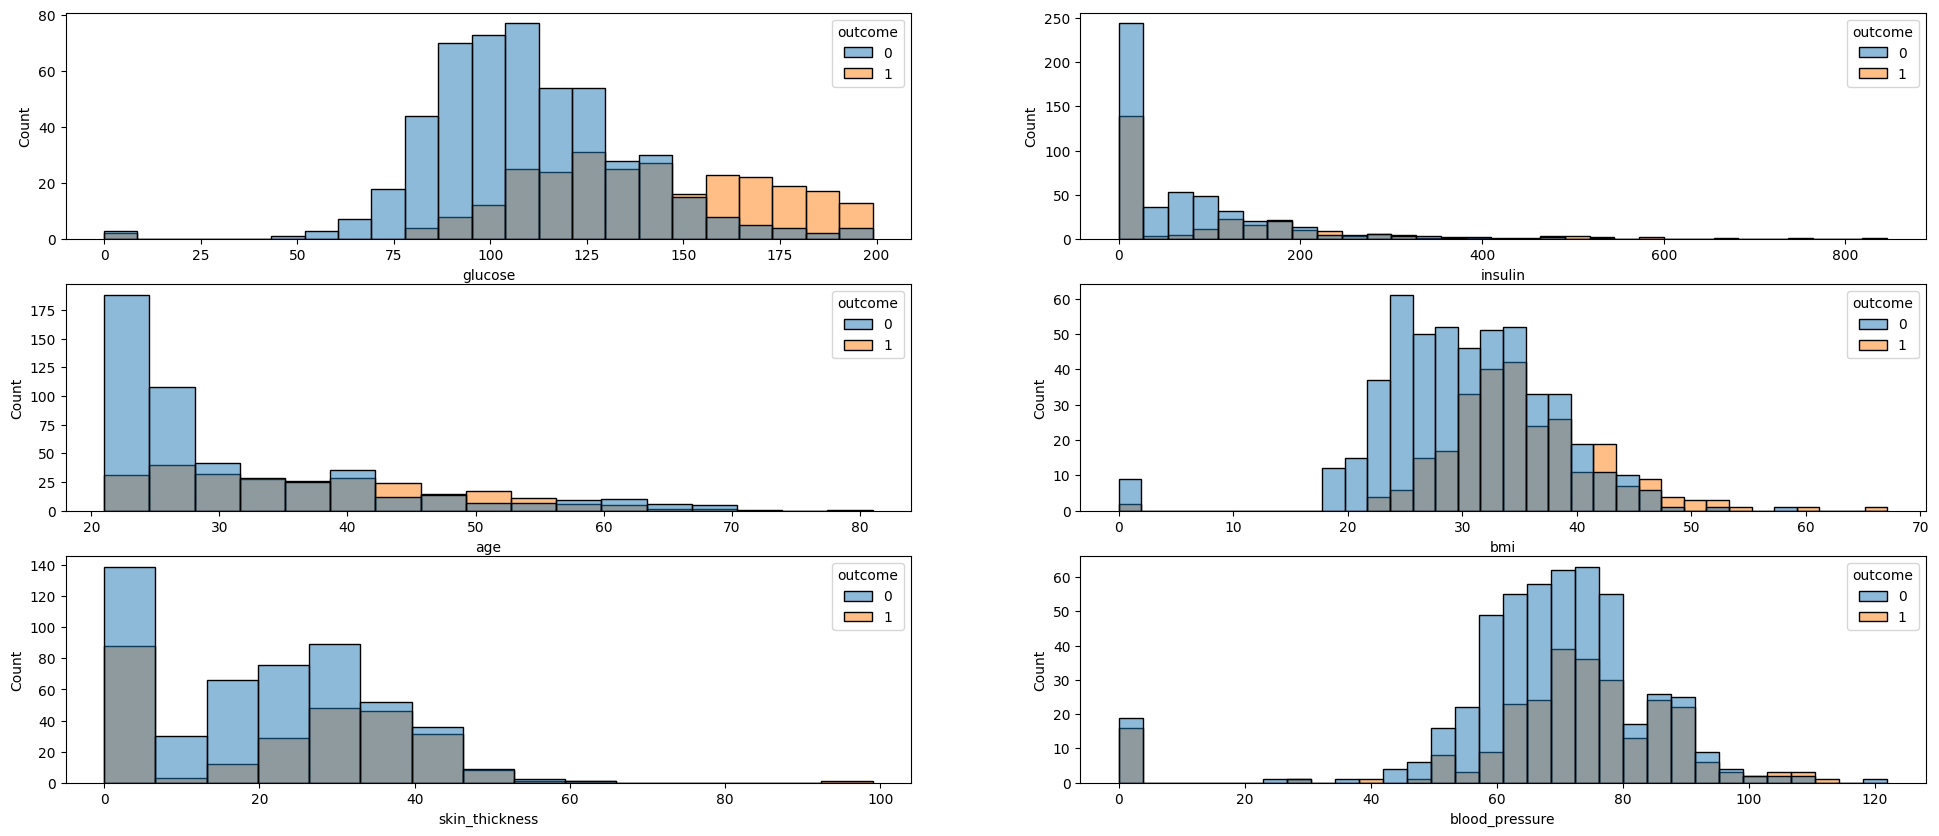

In [3]:
# Twoje rozwiązanie
class_share = df["outcome"].value_counts(normalize=True)
display(class_share)
print(df.isna().sum())
zeros = (df == 0).sum()
display(zeros)

fig, axes = plt.subplots(3, 2, figsize=(24, 10))
sns.histplot(data=df, x=df["glucose"], hue=df["outcome"], ax=axes[0, 0])
sns.histplot(data=df, x=df["insulin"], hue=df["outcome"], ax=axes[0, 1])
sns.histplot(data=df, x=df["age"], hue=df["outcome"], ax=axes[1, 0])
sns.histplot(data=df, x=df["bmi"], hue=df["outcome"], ax=axes[1, 1])
sns.histplot(data=df, x=df["skin_thickness"], hue=df["outcome"], ax=axes[2, 0])
sns.histplot(data=df, x=df["blood_pressure"], hue=df["outcome"], ax=axes[2, 1])
plt.show()

In [4]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
65%
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
niemożliwe w kolumnach "glucose", "blood_pressure", "skin_thickness", insulin", "bmi".
normalne w kolumnach "pregnacies", "outcome"
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?
Najwyraźniej odróznia "glucose".

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [5]:
# Twoje rozwiązanie

df_clean = df.copy()
kolumny_do_zamiany = ['glucose', 'blood_pressure', 'skin_thickness', 'insulin', 'bmi']
df_clean[kolumny_do_zamiany] = df_clean[kolumny_do_zamiany].replace(0, np.nan)
missing = df_clean.isna().sum()
display(missing)
display(df_clean)

,0
pregnancies,0
glucose,5
blood_pressure,35
skin_thickness,227
insulin,374
bmi,11
pedigree,0
age,0
outcome,0


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101.0,76.0,48.0,180.0,32.9,0.171,63,0
764,2,122.0,70.0,27.0,NaN,36.8,0.340,27,0
765,5,121.0,72.0,23.0,112.0,26.2,0.245,30,0
766,1,126.0,60.0,NaN,NaN,30.1,0.349,47,1


In [6]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?
Mamy możliwość usunąć wiersze, wstawić wartość średnią, mediane, mode, mediane w grupach, dodać flagę braku.
Ponieważ insulina ma rozkład skośny wybieramy medianę jako wartość do uzupełnienia.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [7]:
# Twoje rozwiązanie

X = df_clean.drop("outcome", axis=1)
y = df_clean["outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)

def model_z(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), klasyfikator)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

,CV średnia,CV odch.,train
baseline,0.651049,0.002249,0.651042
regresja logistyczna,0.777856,0.024709,0.789931
kNN,0.736132,0.020716,0.835069
drzewo decyzyjne,0.713568,0.024244,1.0
las losowy,0.748291,0.014015,1.0


<Axes: >

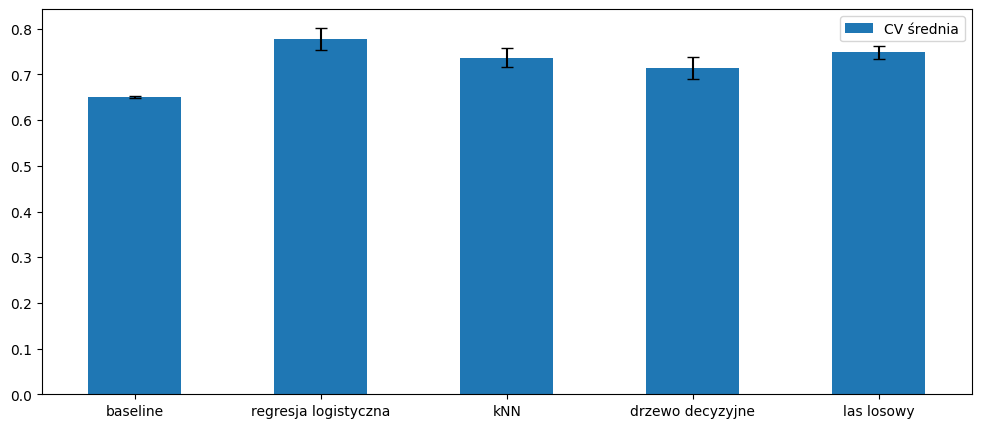

In [9]:
# Twoje rozwiązanie
from sklearn.model_selection import cross_val_score

porownanie = pd.DataFrame(columns=["CV średnia", "CV odch.", "train"], index=["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"])

models = [
    [DummyClassifier(strategy="most_frequent"), "baseline"],
    [LogisticRegression(), "regresja logistyczna"],
    [KNeighborsClassifier(), "kNN"],
    [DecisionTreeClassifier(random_state=42), "drzewo decyzyjne"],
    [RandomForestClassifier(random_state=42), "las losowy"]
]

for model, name in models:
    model_name = name
    model_pipeline = model_z(model)

    cv_scores = cross_val_score(model_pipeline, X_train, y_train, cv=cv, scoring="accuracy")
    porownanie.loc[model_name, "CV średnia"] = cv_scores.mean()
    porownanie.loc[model_name, "CV odch."] = cv_scores.std()
    model_pipeline.fit(X_train, y_train)
    porownanie.loc[model_name, "train"] = model_pipeline.score(X_train, y_train)

display(porownanie)

porownanie[["CV średnia"]].plot.bar(yerr=porownanie["CV odch."], capsize=4, rot=0, figsize=(12, 5))

In [10]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

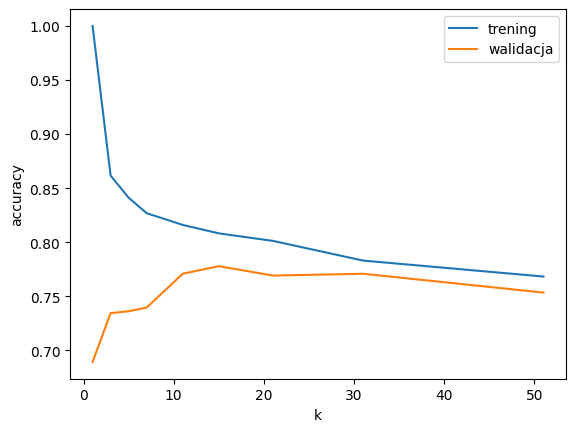

In [11]:
# Twoje rozwiązanie


ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]
tren, walid = validation_curve(
    model_z(KNeighborsClassifier()), X_train, y_train,
    param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=cv)

plt.plot(ks, tren.mean(axis=1), label="trening")
plt.plot(ks, walid.mean(axis=1), label="walidacja")
plt.xlabel("k")
plt.ylabel("accuracy")
plt.legend()
plt.show()

In [12]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

Dla k=1.0 wynik wynosi dokładnie 1.0 ponieważ przy kNN dla zbioru treningowego oceniającym sąsiadem jest dokładnie ten sam element, wystąpiło zapamiętywanie.

model niedouczony:  k<11;

kmodel przeuczony: k>17;

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [13]:
# Twoje rozwiązanie
siatki = {
    "regresja logistyczna": (LogisticRegression(), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": ks}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42),
                         {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42),
                   {"randomforestclassifier__max_depth": [3, 5, 8, None],
                    "randomforestclassifier__n_estimators": [100, 300]}),
}

wyniki_gs = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(klf), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[nazwa] = gs
    print(f"{nazwa:22s} najlepsze: {gs.best_params_}  CV = {gs.best_score_:.3f}")

regresja logistyczna   najlepsze: {'logisticregression__C': 1}  CV = 0.778
kNN                    najlepsze: {'kneighborsclassifier__n_neighbors': 15}  CV = 0.778
drzewo decyzyjne       najlepsze: {'decisiontreeclassifier__max_depth': 5}  CV = 0.750
las losowy             najlepsze: {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 300}  CV = 0.762


In [14]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

Najlepszy: regresja logistyczna
Najlepszy model: Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(C=1))])


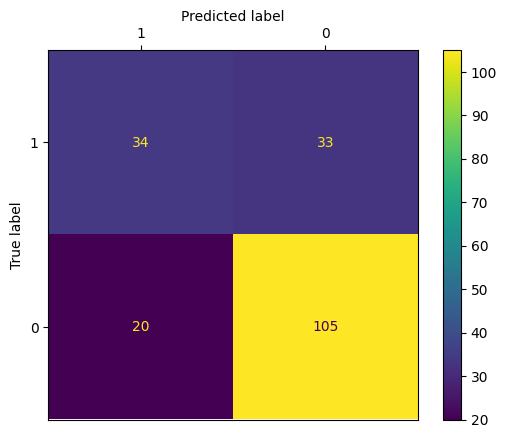

              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



In [15]:
# Twoje rozwiązanie
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_

print(f"Najlepszy: {najlepszy}")
print(f"Najlepszy model: {model_koncowy}")

y_pred = model_koncowy.predict(X_test)
acc_test = model_koncowy.score(X_test, y_test)

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 0])

disp.plot()
disp.ax_.xaxis.tick_top()
disp.ax_.xaxis.set_label_position('top')

plt.show()

print(classification_report(y_test, y_pred))

In [16]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki – ile p.p. to jedna osoba?)

Wynik testowy (0.72) jes mniejszy od walidacji krzyżowej (0.78), różnica wynosi 6 p.p.. Jedna osoba to około 0.52 p.p., co oznacza że różnica odpowiada około 10 pacjentkom. Taka różnica mieści się w granicach błędu statystycznego, nie jest niczym o co można by się było martwić.

2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?

recall dla klasy cukrzyca  wynosi 0.51. oznacza on, że w około 50% przypadków cyukrzycy zostaje oznaczone jako jej brak.

Co do wyboru accuracy wydaje się, że to zalezy co chcemy osiągnąc, ale jeśli zależałoby nam na jak najczęstszym wykrywaniu cukrzycy, to wtedy nie. Jeśli mielibyśmy oceniać skuteczność ogólnie, to wtedy tak.


3. Modele w czołówce różnią się w CV o 1–2 p.p., a odchylenia wynoszą ok. 2–3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

Nie na tak małym zestawie danych. Na ten moment można jedynie stwierdzić, że są one porównywalnie dobre.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [17]:
#1.
# Twoje rozwiązanie
siatki = {
    "regresja logistyczna": (LogisticRegression(), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": ks}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42),
                         {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42),
                   {"randomforestclassifier__max_depth": [3, 5, 8, None],
                    "randomforestclassifier__n_estimators": [100, 300]}),
}

wyniki_gs = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(klf), siatka, cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_gs[nazwa] = gs
    print(f"{nazwa:22s} najlepsze: {gs.best_params_}  CV = {gs.best_score_:.3f}")

regresja logistyczna   najlepsze: {'logisticregression__C': 1}  CV = 0.583
kNN                    najlepsze: {'kneighborsclassifier__n_neighbors': 3}  CV = 0.597
drzewo decyzyjne       najlepsze: {'decisiontreeclassifier__max_depth': 4}  CV = 0.652
las losowy             najlepsze: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 100}  CV = 0.582


Najlepszy: drzewo decyzyjne
Najlepszy model: Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=4, random_state=42))])


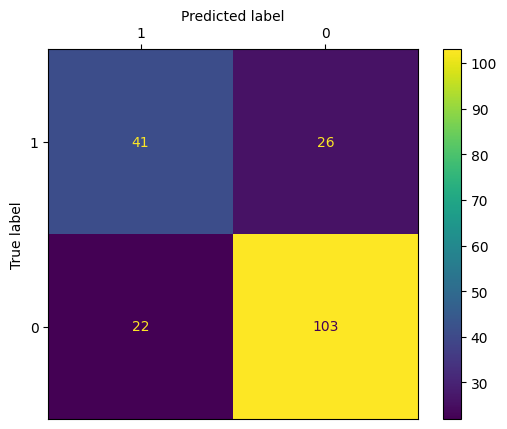

              precision    recall  f1-score   support

           0       0.80      0.82      0.81       125
           1       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192



In [18]:
# Twoje rozwiązanie
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_

print(f"Najlepszy: {najlepszy}")
print(f"Najlepszy model: {model_koncowy}")

y_pred = model_koncowy.predict(X_test)
acc_test = model_koncowy.score(X_test, y_test)

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 0])

disp.plot()
disp.ax_.xaxis.tick_top()
disp.ax_.xaxis.set_label_position('top')

plt.show()

print(classification_report(y_test, y_pred))

MOdel zmienił się na drzewo decyzyjne. Precision lekko się zwiększył, 2p.p. dla klasy 1 i 4p.p. dla klasy 0.

In [19]:
#2.
def model_z_flaga(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), klasyfikator)

wyniki_gs_flaga = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z_flaga(klf), siatka, cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_gs_flaga[nazwa] = gs
    print(f"{nazwa:22s} najlepsze: {gs.best_params_}  CV = {gs.best_score_:.3f}")



regresja logistyczna   najlepsze: {'logisticregression__C': 10}  CV = 0.588
kNN                    najlepsze: {'kneighborsclassifier__n_neighbors': 7}  CV = 0.542
drzewo decyzyjne       najlepsze: {'decisiontreeclassifier__max_depth': 4}  CV = 0.647
las losowy             najlepsze: {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 300}  CV = 0.557


Najlepszy: drzewo decyzyjne
Najlepszy model: Pipeline(steps=[('simpleimputer',
                 SimpleImputer(add_indicator=True, strategy='median')),
                ('standardscaler', StandardScaler()),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=4, random_state=42))])


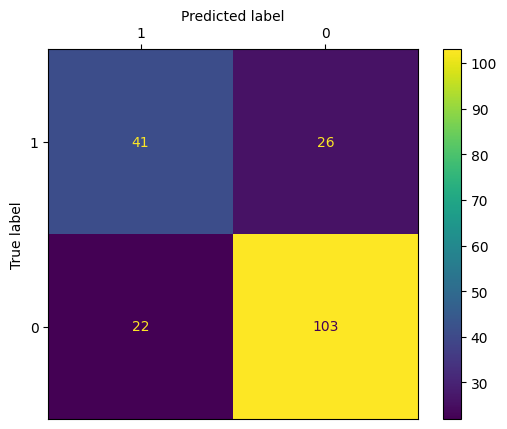

              precision    recall  f1-score   support

           0       0.80      0.82      0.81       125
           1       0.65      0.61      0.63        67

    accuracy                           0.75       192
   macro avg       0.72      0.72      0.72       192
weighted avg       0.75      0.75      0.75       192



In [20]:
# Twoje rozwiązanie
najlepszy = max(wyniki_gs_flaga, key=lambda n: wyniki_gs_flaga[n].best_score_)
model_koncowy = wyniki_gs_flaga[najlepszy].best_estimator_

print(f"Najlepszy: {najlepszy}")
print(f"Najlepszy model: {model_koncowy}")

y_pred = model_koncowy.predict(X_test)
acc_test = model_koncowy.score(X_test, y_test)

cm = confusion_matrix(y_test, y_pred, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 0])

disp.plot()
disp.ax_.xaxis.tick_top()
disp.ax_.xaxis.set_label_position('top')

plt.show()

print(classification_report(y_test, y_pred))

Brak oznaczenia braków nie niesie dodatkowej informacji, wyniki tożsame modelowi bez oznaczania flag.

,0
pregnancies,111
glucose,5
blood_pressure,35
skin_thickness,227
insulin,374
bmi,11
pedigree,0
age,0
outcome,500


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


,CV średnia,CV odch.,train
baseline,0.651049,0.002249,0.651042
regresja logistyczna,0.777826,0.016291,0.795139
kNN,0.734408,0.040768,0.8125
drzewo decyzyjne,0.678831,0.009062,1.0
las losowy,0.755202,0.027206,1.0


regresja logistyczna   najlepsze: {'logisticregression__C': 10}  CV = 0.780
kNN                    najlepsze: {'kneighborsclassifier__n_neighbors': 11}  CV = 0.755
drzewo decyzyjne       najlepsze: {'decisiontreeclassifier__max_depth': 2}  CV = 0.740
las losowy             najlepsze: {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 100}  CV = 0.762
Najlepszy: regresja logistyczna
Najlepszy model: Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(C=10))])


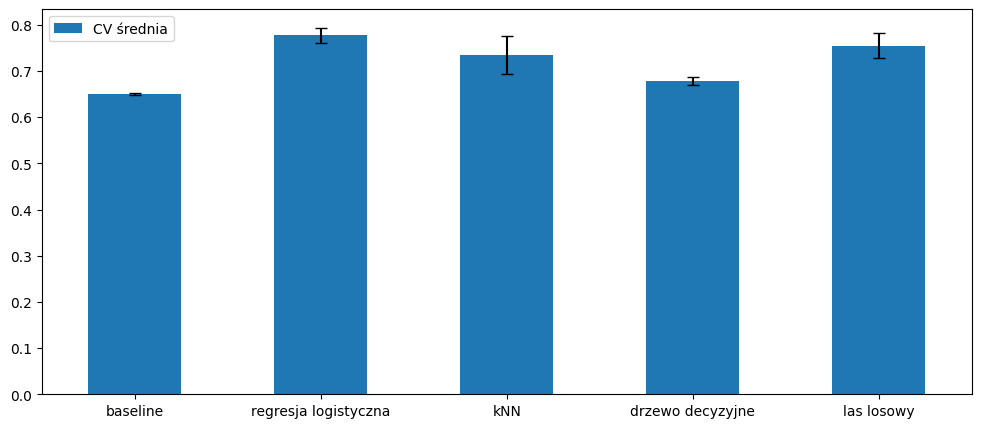

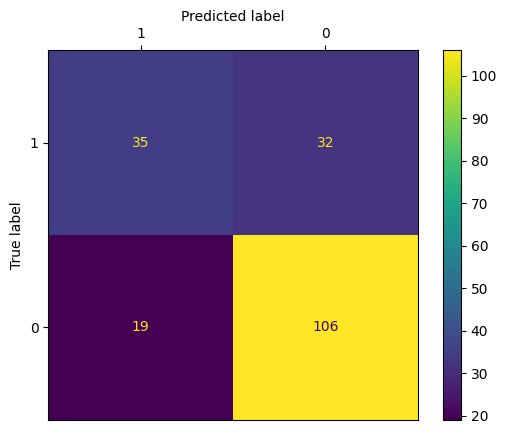

              precision    recall  f1-score   support

           0       0.77      0.85      0.81       125
           1       0.65      0.52      0.58        67

    accuracy                           0.73       192
   macro avg       0.71      0.69      0.69       192
weighted avg       0.73      0.73      0.73       192



In [21]:
#3.
df_raw = df.copy()
zero_raw = (df_raw == 0).sum()
display(zero_raw)
display(df_raw)

#4 Twoje rozwiązanie
X_raw = df_raw.drop("outcome", axis=1)
y_raw = df_raw["outcome"]

X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(X_raw, y_raw, test_size=0.25, stratify=y_raw, random_state=42)

def model_z_raw(klasyfikator):
    return make_pipeline(StandardScaler(), klasyfikator)

cv_raw = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#5 Twoje rozwiązanie
porownanie_raw = pd.DataFrame(columns=["CV średnia", "CV odch.", "train"], index=["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"])

models_raw = [
    [DummyClassifier(strategy="most_frequent"), "baseline"],
    [LogisticRegression(), "regresja logistyczna"],
    [KNeighborsClassifier(), "kNN"],
    [DecisionTreeClassifier(random_state=42), "drzewo decyzyjne"],
    [RandomForestClassifier(random_state=42), "las losowy"]
]

for model, name in models_raw:
    model_name_raw = name
    model_pipeline_raw = model_z_raw(model)

    cv_scores_raw = cross_val_score(model_pipeline_raw, X_train_raw, y_train_raw, cv=cv_raw, scoring="accuracy")
    porownanie_raw.loc[model_name_raw, "CV średnia"] = cv_scores_raw.mean()
    porownanie_raw.loc[model_name_raw, "CV odch."] = cv_scores_raw.std()
    model_pipeline_raw.fit(X_train_raw, y_train_raw)
    porownanie_raw.loc[model_name_raw, "train"] = model_pipeline_raw.score(X_train_raw, y_train_raw)

display(porownanie_raw)

porownanie_raw[["CV średnia"]].plot.bar(yerr=porownanie_raw["CV odch."], capsize=4, rot=0, figsize=(12, 5))

#7 Twoje rozwiązanie
siatki_raw = {
    "regresja logistyczna": (LogisticRegression(), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": ks}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42),
                         {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42),
                   {"randomforestclassifier__max_depth": [3, 5, 8, None],
                    "randomforestclassifier__n_estimators": [100, 300]}),
}

wyniki_gs_raw = {}
for nazwa, (klf, siatka) in siatki_raw.items():
    gs_raw = GridSearchCV(model_z_raw(klf), siatka, cv=cv_raw)
    gs_raw.fit(X_train_raw, y_train_raw)
    wyniki_gs_raw[nazwa] = gs_raw
    print(f"{nazwa:22s} najlepsze: {gs_raw.best_params_}  CV = {gs_raw.best_score_:.3f}")

#8. Twoje rozwiązanie
najlepszy = max(wyniki_gs_raw, key=lambda n: wyniki_gs_raw[n].best_score_)
model_koncowy = wyniki_gs_raw[najlepszy].best_estimator_

print(f"Najlepszy: {najlepszy}")
print(f"Najlepszy model: {model_koncowy}")

y_pred = model_koncowy.predict(X_test_raw)
acc_test = model_koncowy.score(X_test_raw, y_test_raw)

cm = confusion_matrix(y_test_raw, y_pred, labels=[1, 0])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 0])

disp.plot()
disp.ax_.xaxis.tick_top()
disp.ax_.xaxis.set_label_position('top')

plt.show()

print(classification_report(y_test, y_pred))

Brak pominięcia 0 daje małą różnicę. Najlepsza okazała się regresja logistyczna osiągając wynik walidacji krzyżowej 0.78, praktycznie taki sam jak przy pominięciu 0. Różnica może być mała ponieważ standaryzujemy dane co może zmniejszać wpływ skrajnych wartości jak 0 na wagi modelu.